In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
years= [2020, 2023, 2025, 2026]
df_list= [pd.read_csv(f'Analysis_{year}.csv',delimiter=";") for year in years]

In [ ]:
solaris_df= pd.concat(df_list,axis=0)
solaris_df= solaris_df.rename(columns= {solaris_df.columns[0]: "Date"})
solaris_df.head()

,Date,CIU Arazi / Total yield / Mean values [kWh],INV NO:01 / Total yield / Mean values [kWh],INV NO:02 / Total yield / Mean values [kWh],INV NO:03 / Total yield / Mean values [kWh],INV NO:04 / Total yield / Mean values [kWh],INV NO:05 / Total yield / Mean values [kWh],INV NO:06 / Total yield / Mean values [kWh],INV NO:07 / Total yield / Mean values [kWh],INV NO:08 / Total yield / Mean values [kWh],...,INV NO:21 / Total yield / Mean values [kWh],INV NO:22 / Total yield / Mean values [kWh],INV NO:23 / Total yield / Mean values [kWh],INV NO:24 / Total yield / Mean values [kWh],INV NO:25 / Total yield / Mean values [kWh],INV NO:26 / Total yield / Mean values [kWh],INV NO:27 / Total yield / Mean values [kWh],INV NO:28 / Total yield / Mean values [kWh],INV NO:29 / Total yield / Mean values [kWh],INV NO:30 / Total yield / Mean values [kWh]
0,"=""Jan 20""",,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,"=""Feb 20""",,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,"=""Mar 20""","22,068.43",734.35,728.76,744.70,618.65,726.64,767.26,740.53,735.41,...,732.45,658.06,742.95,737.24,726.24,725.03,743.60,727.06,744.99,750.08
3,"=""Apr 20""","112,643.50","3,910.46","3,694.64","3,804.80","3,169.75","3,824.68","3,853.56","3,716.23","3,779.88",...,"3,824.72","3,342.20","3,746.38","3,759.99","3,838.95","3,847.17","3,768.56","3,447.00","3,752.57","3,785.21"
4,"=""May 20""","128,155.62","4,426.73","4,222.64","4,279.94","3,524.46","4,357.48","4,322.36","4,177.25","4,243.38",...,"4,374.16","3,754.60","4,277.00","4,305.26","4,374.16","4,406.01","4,309.38","4,179.59","4,294.85","4,329.40"


In [ ]:
solaris_df['Date']= (solaris_df['Date'].astype(str)
.str.replace('=','',regex=False)
.str.replace('"', '', regex=False).str.strip()
)
solaris_df.head()

,Date,CIU Arazi / Total yield / Mean values [kWh],INV NO:01 / Total yield / Mean values [kWh],INV NO:02 / Total yield / Mean values [kWh],INV NO:03 / Total yield / Mean values [kWh],INV NO:04 / Total yield / Mean values [kWh],INV NO:05 / Total yield / Mean values [kWh],INV NO:06 / Total yield / Mean values [kWh],INV NO:07 / Total yield / Mean values [kWh],INV NO:08 / Total yield / Mean values [kWh],...,INV NO:21 / Total yield / Mean values [kWh],INV NO:22 / Total yield / Mean values [kWh],INV NO:23 / Total yield / Mean values [kWh],INV NO:24 / Total yield / Mean values [kWh],INV NO:25 / Total yield / Mean values [kWh],INV NO:26 / Total yield / Mean values [kWh],INV NO:27 / Total yield / Mean values [kWh],INV NO:28 / Total yield / Mean values [kWh],INV NO:29 / Total yield / Mean values [kWh],INV NO:30 / Total yield / Mean values [kWh]
0,Jan 20,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Feb 20,,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Mar 20,"22,068.43",734.35,728.76,744.70,618.65,726.64,767.26,740.53,735.41,...,732.45,658.06,742.95,737.24,726.24,725.03,743.60,727.06,744.99,750.08
3,Apr 20,"112,643.50","3,910.46","3,694.64","3,804.80","3,169.75","3,824.68","3,853.56","3,716.23","3,779.88",...,"3,824.72","3,342.20","3,746.38","3,759.99","3,838.95","3,847.17","3,768.56","3,447.00","3,752.57","3,785.21"
4,May 20,"128,155.62","4,426.73","4,222.64","4,279.94","3,524.46","4,357.48","4,322.36","4,177.25","4,243.38",...,"4,374.16","3,754.60","4,277.00","4,305.26","4,374.16","4,406.01","4,309.38","4,179.59","4,294.85","4,329.40"


In [ ]:
for col in solaris_df.columns[1:]:
    solaris_df[col] = solaris_df[col].astype(str).str.replace(',', '', regex=False).str.strip()
    solaris_df[col] = pd.to_numeric(solaris_df[col], errors='coerce')

In [ ]:
solaris_df['Datetime'] = pd.to_datetime(solaris_df['Date'], format='%b %y')
solar_analysis = solaris_df.sort_values('Datetime').reset_index(drop=True)
solar_analysis['Month'] = solar_analysis['Datetime'].dt.strftime('%b')
solar_analysis['Year'] = solar_analysis['Datetime'].dt.year

solar_analysis.to_csv('solar_analysis_final_data.csv', index=False)

In [ ]:
missing_values = solar_analysis.isnull().sum()
total_cells = np.prod(solar_analysis.shape)
total_missing = missing_values.sum()
print(f"Missing Data Percentage: {(total_missing / total_cells) * 100:.2f}%")

Missing Data Percentage: 20.54%


In [ ]:
inverter_cols = [col for col in solar_analysis.columns if 'INV NO:' in col]

all_column_stats = []
for col in inverter_cols:
    column = solar_analysis[col].dropna()

    if not column.empty:
        counts = column.value_counts()
        has_mode = not counts.empty and counts.max() > 1
        q1, q3 = column.quantile(0.25), column.quantile(0.75)

        stats = {
            'Inverter': col,
            'mean': column.mean(),
            'std': column.std(),
            'variance': column.var(),
            'skewness': column.skew(),
            'kurtosis': column.kurtosis(),
            'Q1': q1,
            'Q3': q3,
            'IQR': q3 - q1,
            'min': column.min(),
            'max': column.max(),
            'median': column.median(),
            'mode': column.mode().iloc[0] if has_mode else None,
            'range': column.max() - column.min()
        }
    else:
        stats = {k: None for k in ['mean', 'std', 'variance', 'skewness', 'kurtosis', 'Q1', 'Q3', 'IQR', 'min', 'max', 'median', 'mode', 'range']}
        stats['Inverter'] = col

    all_column_stats.append(stats)

inverter_stats = pd.DataFrame(all_column_stats)
inverter_stats.to_csv('inverter_descriptive_statistics.csv', index=False)
display(inverter_stats)

,Inverter,mean,std,variance,skewness,kurtosis,Q1,Q3,IQR,min,max,median,mode,range
0,INV NO:01 / Total yield / Mean values [kWh],3014.502703,1275.230380,1.626213e+06,-0.905474,-0.231102,2058.0400,4005.15,1947.1100,87.90,4459.40,3537.64,NaN,4371.50
1,INV NO:02 / Total yield / Mean values [kWh],2825.402973,1257.889574,1.582286e+06,-0.692865,-0.617161,1834.3900,3883.54,2049.1500,83.13,4316.15,3316.23,NaN,4233.02
2,INV NO:03 / Total yield / Mean values [kWh],2941.882432,1218.952059,1.485844e+06,-0.971227,-0.116792,2117.8700,3865.78,1747.9100,100.89,4279.94,3563.25,NaN,4179.05
3,INV NO:04 / Total yield / Mean values [kWh],2404.695135,1032.067596,1.065164e+06,-0.797585,-0.319824,1773.2900,3275.20,1501.9100,81.99,3592.11,2724.49,NaN,3510.12
4,INV NO:05 / Total yield / Mean values [kWh],2746.756486,1307.229100,1.708848e+06,-0.617915,-0.903332,1780.6600,3697.33,1916.6700,70.47,4419.85,3301.39,NaN,4349.38
5,INV NO:06 / Total yield / Mean values [kWh],3154.471471,1098.766740,1.207288e+06,-0.791077,-0.408059,2187.7850,4035.03,1847.2450,495.33,4397.34,3650.91,NaN,3902.01
6,INV NO:07 / Total yield / Mean values [kWh],3037.096486,1129.074688,1.274810e+06,-1.114338,0.387823,2156.1600,3866.06,1709.9000,107.11,4232.26,3508.41,NaN,4125.15
7,INV NO:08 / Total yield / Mean values [kWh],2973.618649,1201.562499,1.443752e+06,-0.870943,-0.344676,2124.9000,3937.68,1812.7800,99.89,4332.68,3474.44,NaN,4232.79
8,INV NO:09 / Total yield / Mean values [kWh],3073.111892,1199.966948,1.439921e+06,-0.974540,-0.073603,2177.8600,4002.57,1824.7100,87.42,4381.91,3619.26,NaN,4294.49
9,INV NO:10 / Total yield / Mean values [kWh],3070.094865,1194.142132,1.425975e+06,-0.992878,0.003878,2155.1100,3990.18,1835.0700,96.08,4381.05,3586.82,NaN,4284.97


In [ ]:
inverter_data = solar_analysis[inverter_cols]

q1 = inverter_data.quantile(0.25, axis=1)
q3 = inverter_data.quantile(0.75, axis=1)

months_stats = pd.DataFrame({
    'Month': solar_analysis['Month'],
    'Year': solar_analysis['Year'],
    'mean': inverter_data.mean(axis=1),
    'variance': inverter_data.var(axis=1),
    'skewness': inverter_data.skew(axis=1),
    'kurtosis': inverter_data.kurtosis(axis=1),
    'std': inverter_data.std(axis=1),
    'min': inverter_data.min(axis=1),
    'max': inverter_data.max(axis=1),
    'Q1': q1,
    'Q3': q3,
    'IQR': q3 - q1,
    'median': inverter_data.median(axis=1),
    'mode': inverter_data.apply(lambda r: r.mode().iloc[0] if (not r.dropna().empty and r.value_counts().max() > 1) else None, axis=1),
    'range': inverter_data.max(axis=1) - inverter_data.min(axis=1)
})

month_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
months_stats['Month'] = pd.Categorical(months_stats['Month'], categories=month_order, ordered=True)
months_stats = months_stats.sort_values(by=['Month', 'Year']).reset_index(drop=True)

months_stats.to_csv('monthly_yearly_descriptive_statistics.csv', index=False)
display(months_stats)

,Month,Year,mean,variance,skewness,kurtosis,std,min,max,Q1,Q3,IQR,median,mode,range
0,Jan,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Jan,2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Jan,2025,96.701379,125.285155,-0.693099,-0.447456,11.193085,70.47,111.04,87.9000,106.0500,18.1500,99.370,NaN,40.57
3,Jan,2026,1974.087667,177357.880239,-3.541554,15.246976,421.138790,53.77,2271.81,1848.9750,2197.0525,348.0775,2117.940,NaN,2218.04
4,Feb,2020,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,Feb,2023,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,Feb,2025,2234.768333,317735.652863,-1.080442,0.149356,563.680453,830.51,2753.01,1692.0025,2659.8975,967.8950,2502.110,NaN,1922.50
7,Feb,2026,2671.735333,41046.921695,-1.843392,3.845446,202.600399,1977.04,2886.85,2592.5500,2794.5975,202.0475,2742.625,NaN,909.81
8,Mar,2020,735.613667,834.605969,-3.048456,10.376807,28.889548,618.65,767.26,732.7825,750.3650,17.5825,743.275,NaN,148.61
9,Mar,2023,1731.887667,255671.119281,-2.799218,6.690917,505.639317,0.00,1968.76,1851.6675,1936.4225,84.7550,1912.880,NaN,1968.76


In [ ]:
total_yield_col = 'CIU Arazi / Total yield / Mean values [kWh]'

monthly_yearly_total_yield = solar_analysis.groupby(['Year', 'Month'], observed=False)[total_yield_col].sum().reset_index()
monthly_yearly_total_yield['Month'] = pd.Categorical(monthly_yearly_total_yield['Month'], categories=month_order, ordered=True)
monthly_yearly_total_yield = monthly_yearly_total_yield.sort_values(by=['Year', 'Month']).reset_index(drop=True)
display(monthly_yearly_total_yield)

,Year,Month,CIU Arazi / Total yield / Mean values [kWh]
0,2020,Jan,0.00
1,2020,Feb,0.00
2,2020,Mar,22068.43
3,2020,Apr,112643.50
4,2020,May,128155.62
5,2020,Jun,124620.91
6,2020,Jul,122331.75
7,2020,Aug,105874.11
8,2020,Sep,105243.73
9,2020,Oct,103555.96


In [ ]:
season_map = {
    'Dec': 'Winter', 'Jan': 'Winter', 'Feb': 'Winter',
    'Mar': 'Spring', 'Apr': 'Spring', 'May': 'Spring',
    'Jun': 'Summer', 'Jul': 'Summer', 'Aug': 'Summer',
    'Sep': 'Autumn', 'Oct': 'Autumn', 'Nov': 'Autumn'
}
season_order = ['Winter', 'Spring', 'Summer', 'Autumn']

In [ ]:
monthly_yearly_total_yield['Season'] = monthly_yearly_total_yield['Month'].map(season_map)
seasonal_yield_by_year = (
    monthly_yearly_total_yield
    .groupby(['Year', 'Season'], observed=False)[total_yield_col]
    .sum()
    .reset_index()
    .rename(columns={total_yield_col: 'Total Yield [kWh]'})
)

seasonal_yield_by_year['Season'] = pd.Categorical(seasonal_yield_by_year['Season'], categories=season_order, ordered=True)
seasonal_yield_by_year = seasonal_yield_by_year.sort_values(by=['Year', 'Season']).reset_index(drop=True)
display(seasonal_yield_by_year)

,Year,Season,Total Yield [kWh]
0,2020,Winter,54770.89
1,2020,Spring,262867.55
2,2020,Summer,352826.77
3,2020,Autumn,267969.11
4,2023,Winter,14076.90
5,2023,Spring,275139.45
6,2023,Summer,366311.27
7,2023,Autumn,283398.00
8,2025,Winter,122527.84
9,2025,Spring,333781.68


In [ ]:
inverter_sums = solar_analysis[inverter_cols].sum().reset_index()
inverter_sums.columns = ['Inverter', 'Total Yield [kWh]']

total_site_yield = solar_analysis[total_yield_col].sum()
inverter_sums['Percentage'] = (inverter_sums['Total Yield [kWh]'] / total_site_yield) * 100
display(inverter_sums)

,Inverter,Total Yield [kWh],Percentage
0,INV NO:01 / Total yield / Mean values [kWh],111536.60,3.379672
1,INV NO:02 / Total yield / Mean values [kWh],104539.91,3.167665
2,INV NO:03 / Total yield / Mean values [kWh],108849.65,3.298255
3,INV NO:04 / Total yield / Mean values [kWh],88973.72,2.695994
4,INV NO:05 / Total yield / Mean values [kWh],101629.99,3.079492
5,INV NO:06 / Total yield / Mean values [kWh],107252.03,3.249845
6,INV NO:07 / Total yield / Mean values [kWh],112372.57,3.405003
7,INV NO:08 / Total yield / Mean values [kWh],110023.89,3.333836
8,INV NO:09 / Total yield / Mean values [kWh],113705.14,3.445381
9,INV NO:10 / Total yield / Mean values [kWh],113593.51,3.441999


In [ ]:
correlation_matrix = inverter_data.corr()
display(correlation_matrix)

,INV NO:01 / Total yield / Mean values [kWh],INV NO:02 / Total yield / Mean values [kWh],INV NO:03 / Total yield / Mean values [kWh],INV NO:04 / Total yield / Mean values [kWh],INV NO:05 / Total yield / Mean values [kWh],INV NO:06 / Total yield / Mean values [kWh],INV NO:07 / Total yield / Mean values [kWh],INV NO:08 / Total yield / Mean values [kWh],INV NO:09 / Total yield / Mean values [kWh],INV NO:10 / Total yield / Mean values [kWh],...,INV NO:21 / Total yield / Mean values [kWh],INV NO:22 / Total yield / Mean values [kWh],INV NO:23 / Total yield / Mean values [kWh],INV NO:24 / Total yield / Mean values [kWh],INV NO:25 / Total yield / Mean values [kWh],INV NO:26 / Total yield / Mean values [kWh],INV NO:27 / Total yield / Mean values [kWh],INV NO:28 / Total yield / Mean values [kWh],INV NO:29 / Total yield / Mean values [kWh],INV NO:30 / Total yield / Mean values [kWh]
INV NO:01 / Total yield / Mean values [kWh],1.000000,0.980865,0.995464,0.968676,0.927915,0.956774,0.980548,0.980989,0.992843,0.981665,...,0.992423,0.950544,0.979257,0.977924,0.992357,0.977521,0.948726,0.977932,0.981102,0.849255
INV NO:02 / Total yield / Mean values [kWh],0.980865,1.000000,0.973671,0.967440,0.904739,0.950212,0.976875,0.981025,0.974494,0.980585,...,0.971703,0.943935,0.974795,0.973625,0.975553,0.952665,0.929387,0.972011,0.975366,0.848943
INV NO:03 / Total yield / Mean values [kWh],0.995464,0.973671,1.000000,0.971591,0.931111,0.953260,0.979204,0.974653,0.989396,0.979443,...,0.990778,0.949731,0.978116,0.977769,0.989144,0.969843,0.946094,0.977345,0.981028,0.848002
INV NO:04 / Total yield / Mean values [kWh],0.968676,0.967440,0.971591,1.000000,0.887407,0.920984,0.959446,0.951247,0.961076,0.959856,...,0.959905,0.931101,0.957707,0.957592,0.961010,0.932370,0.946123,0.972270,0.961094,0.817236
INV NO:05 / Total yield / Mean values [kWh],0.927915,0.904739,0.931111,0.887407,1.000000,0.857851,0.901202,0.907708,0.922752,0.904603,...,0.922887,0.866511,0.898370,0.897041,0.921407,0.911031,0.875087,0.894481,0.887937,0.775057
INV NO:06 / Total yield / Mean values [kWh],0.956774,0.950212,0.953260,0.920984,0.857851,1.000000,0.962026,0.958094,0.956818,0.963776,...,0.963628,0.924791,0.961355,0.959579,0.957382,0.935338,0.891807,0.951660,0.961450,0.886081
INV NO:07 / Total yield / Mean values [kWh],0.980548,0.976875,0.979204,0.959446,0.901202,0.962026,1.000000,0.991434,0.987444,0.998223,...,0.985982,0.976322,0.999262,0.997478,0.987939,0.958799,0.943814,0.989445,0.997541,0.874743
INV NO:08 / Total yield / Mean values [kWh],0.980989,0.981025,0.974653,0.951247,0.907708,0.958094,0.991434,1.000000,0.984625,0.996486,...,0.985242,0.961024,0.990295,0.987715,0.984759,0.969604,0.931354,0.986227,0.992103,0.873616
INV NO:09 / Total yield / Mean values [kWh],0.992843,0.974494,0.989396,0.961076,0.922752,0.956818,0.987444,0.984625,1.000000,0.987592,...,0.997684,0.960869,0.986551,0.984952,0.999405,0.982726,0.958957,0.981802,0.985062,0.876743
INV NO:10 / Total yield / Mean values [kWh],0.981665,0.980585,0.979443,0.959856,0.904603,0.963776,0.998223,0.996486,0.987592,1.000000,...,0.987115,0.971731,0.997496,0.995778,0.987895,0.963043,0.940325,0.991272,0.998159,0.876892


In [ ]:
outlier_counts= {}
for col in inverter_cols:
    q1 = inverter_data[col].quantile(0.25)
    q3 = inverter_data[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_counts[col] = outliers = ((inverter_data[col] < lower_bound) | (inverter_data[col] > upper_bound)).sum()

outlier_df = pd.DataFrame(list(outlier_counts.items()), columns=['Inverter', 'Outlier Count'])
display(outlier_df)

,Inverter,Outlier Count
0,INV NO:01 / Total yield / Mean values [kWh],0
1,INV NO:02 / Total yield / Mean values [kWh],0
2,INV NO:03 / Total yield / Mean values [kWh],0
3,INV NO:04 / Total yield / Mean values [kWh],0
4,INV NO:05 / Total yield / Mean values [kWh],0
5,INV NO:06 / Total yield / Mean values [kWh],0
6,INV NO:07 / Total yield / Mean values [kWh],0
7,INV NO:08 / Total yield / Mean values [kWh],0
8,INV NO:09 / Total yield / Mean values [kWh],0
9,INV NO:10 / Total yield / Mean values [kWh],0


In [ ]:
monthly_median = inverter_data.median(axis=1)

relative_performance = inverter_data.div(monthly_median, axis=0)
relative_performance['Date_Str']  = solar_analysis['Datetime'].dt.strftime('%b %y')
display(relative_performance)

,INV NO:01 / Total yield / Mean values [kWh],INV NO:02 / Total yield / Mean values [kWh],INV NO:03 / Total yield / Mean values [kWh],INV NO:04 / Total yield / Mean values [kWh],INV NO:05 / Total yield / Mean values [kWh],INV NO:06 / Total yield / Mean values [kWh],INV NO:07 / Total yield / Mean values [kWh],INV NO:08 / Total yield / Mean values [kWh],INV NO:09 / Total yield / Mean values [kWh],INV NO:10 / Total yield / Mean values [kWh],...,INV NO:22 / Total yield / Mean values [kWh],INV NO:23 / Total yield / Mean values [kWh],INV NO:24 / Total yield / Mean values [kWh],INV NO:25 / Total yield / Mean values [kWh],INV NO:26 / Total yield / Mean values [kWh],INV NO:27 / Total yield / Mean values [kWh],INV NO:28 / Total yield / Mean values [kWh],INV NO:29 / Total yield / Mean values [kWh],INV NO:30 / Total yield / Mean values [kWh],Date_Str
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Jan 20
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Feb 20
2,0.987992,0.980472,1.001917,0.832330,0.977619,1.032269,0.996307,0.989418,1.009573,0.987225,...,0.885352,0.999563,0.991881,0.977081,0.975453,1.000437,0.978184,1.002307,1.009155,Mar 20
3,1.032548,0.975561,1.004649,0.836965,1.009898,1.017524,0.981262,0.998068,1.024209,1.011746,...,0.882500,0.989223,0.992817,1.013666,1.015836,0.995079,0.910172,0.990857,0.999476,Apr 20
4,1.025397,0.978122,0.991395,0.816397,1.009356,1.001221,0.967608,0.982926,1.008378,0.999275,...,0.869706,0.990714,0.997260,1.013220,1.020597,0.998214,0.968150,0.994848,1.002851,May 20
5,1.003339,1.013823,1.013615,0.843477,0.987086,1.033792,0.999063,0.995511,0.988432,1.019971,...,0.995832,0.984360,0.985763,0.986471,0.928621,0.990221,0.943362,0.984587,0.987282,Jun 20
6,1.050816,0.998727,1.018539,0.838771,1.031384,1.027387,0.988272,1.006682,1.026253,1.019990,...,1.008612,0.969857,0.973423,0.984740,0.920823,0.982785,0.956233,0.971430,0.978192,Jul 20
7,1.045195,0.980905,1.019216,0.840704,1.015540,1.031706,0.988967,0.996606,1.024296,1.013316,...,1.013669,0.971611,0.971203,0.987011,0.987766,0.988192,0.975121,0.970416,0.985703,Aug 20
8,1.003090,0.939226,0.994058,0.811284,0.956236,1.004323,0.963549,0.958171,0.998110,0.989163,...,1.030844,1.004008,1.008341,1.001615,1.011534,1.015566,1.000153,0.997718,1.029413,Sep 20
9,0.976496,0.915380,0.983565,0.815096,0.940847,1.014751,0.976587,0.943831,1.009264,0.986963,...,1.026361,1.005990,1.002252,1.000091,0.995167,1.016148,0.982905,0.985969,1.016849,Oct 20


In [ ]:
annual_yield = solar_analysis.groupby('Year')[total_yield_col].sum().reset_index()
annual_yield['annual_change']= annual_yield[total_yield_col].pct_change() * 100
display(annual_yield)

,Year,CIU Arazi / Total yield / Mean values [kWh],annual_change
0,2020,938434.32,NaN
1,2023,938925.62,0.052353
2,2025,1098656.18,17.012057
3,2026,324203.39,-70.490915


In [ ]:
solar_analysis['Fleet_Mean'] = inverter_data.mean(axis=1)
solar_analysis['Fleet_Std'] = inverter_data.std(axis=1)
solar_analysis['Fleet_CV'] = solar_analysis['Fleet_Std'] / solar_analysis['Fleet_Mean']

fault_months = solar_analysis[solar_analysis['Fleet_CV'] > 0.15][['Datetime', 'Month', 'Year', 'Fleet_Mean', 'Fleet_Std', 'Fleet_CV']]

print("Months with high fleet variance potential faults:")
display(fault_months.sort_values('Fleet_CV', ascending=False))

Months with high fleet variance potential faults:


,Datetime,Month,Year,Fleet_Mean,Fleet_Std,Fleet_CV
40,2026-05-01,May,2026,877.147500,411.245514,0.468844
11,2020-12-01,Dec,2020,1825.697333,563.892078,0.308864
14,2023-03-01,Mar,2023,1731.887667,505.639317,0.291958
25,2025-02-01,Feb,2025,2234.768333,563.680453,0.252232
10,2020-11-01,Nov,2020,1972.314667,437.551930,0.221847
36,2026-01-01,Jan,2026,1974.087667,421.138790,0.213333
23,2023-12-01,Dec,2023,469.230667,94.405082,0.201191
9,2020-10-01,Oct,2020,3451.866000,670.445755,0.194227
35,2025-12-01,Dec,2025,1756.017333,327.861684,0.186708
39,2026-04-01,Apr,2026,2072.217000,335.466185,0.161888


In [ ]:
solar_analysis.drop(columns=['Fleet_Mean' ,'Fleet_Std', 'Fleet_CV'], inplace=True)

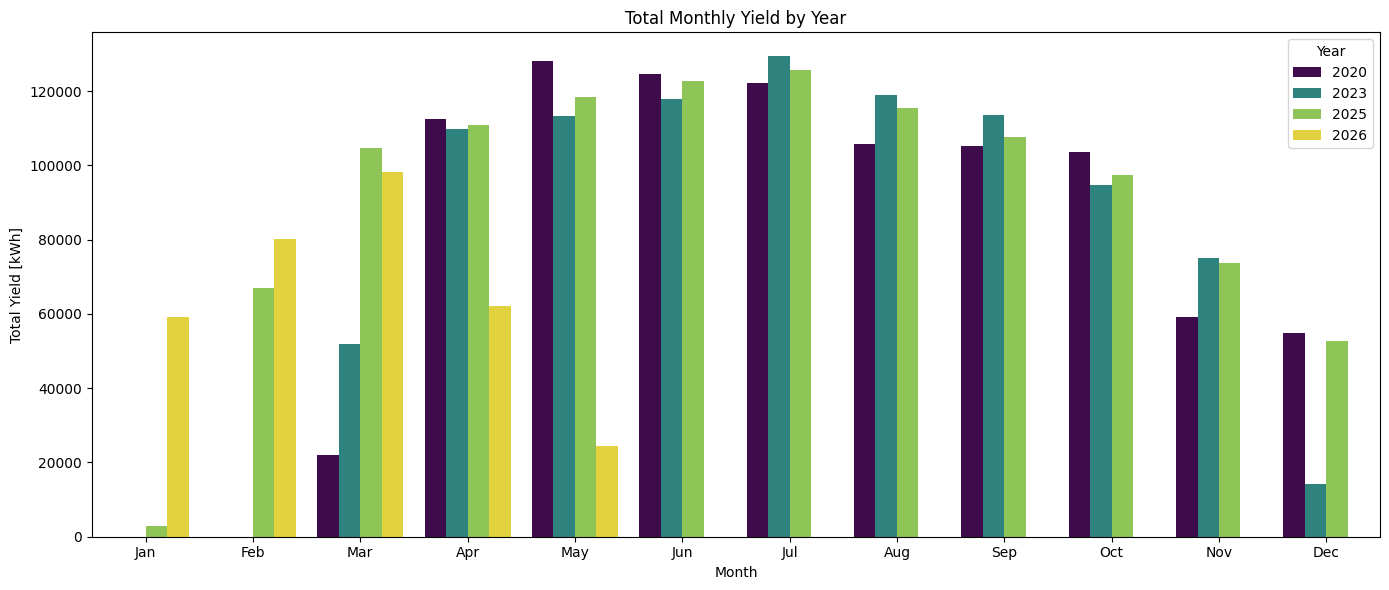

In [ ]:
plt.figure(figsize=(14, 6))
sns.barplot(x='Month', y=total_yield_col, hue='Year', data=monthly_yearly_total_yield, palette='viridis')
plt.title('Total Monthly Yield by Year')
plt.xlabel('Month')
plt.ylabel('Total Yield [kWh]')
plt.legend(title='Year')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2128/1298755770.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Inverter', y='Total Yield [kWh]', data=inverter_sums, palette='viridis')


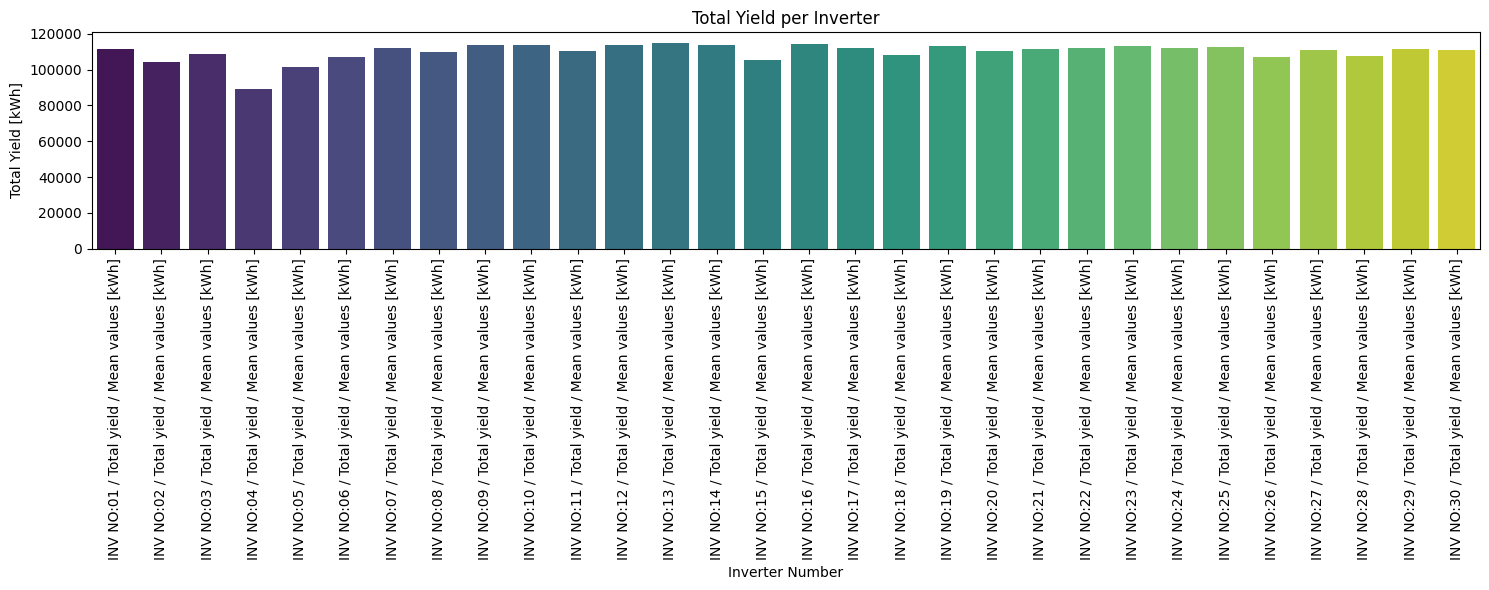

In [ ]:
plt.figure(figsize=(15, 6))
sns.barplot(x='Inverter', y='Total Yield [kWh]', data=inverter_sums, palette='viridis')
plt.title('Total Yield per Inverter')
plt.xlabel('Inverter Number')
plt.ylabel('Total Yield [kWh]')
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

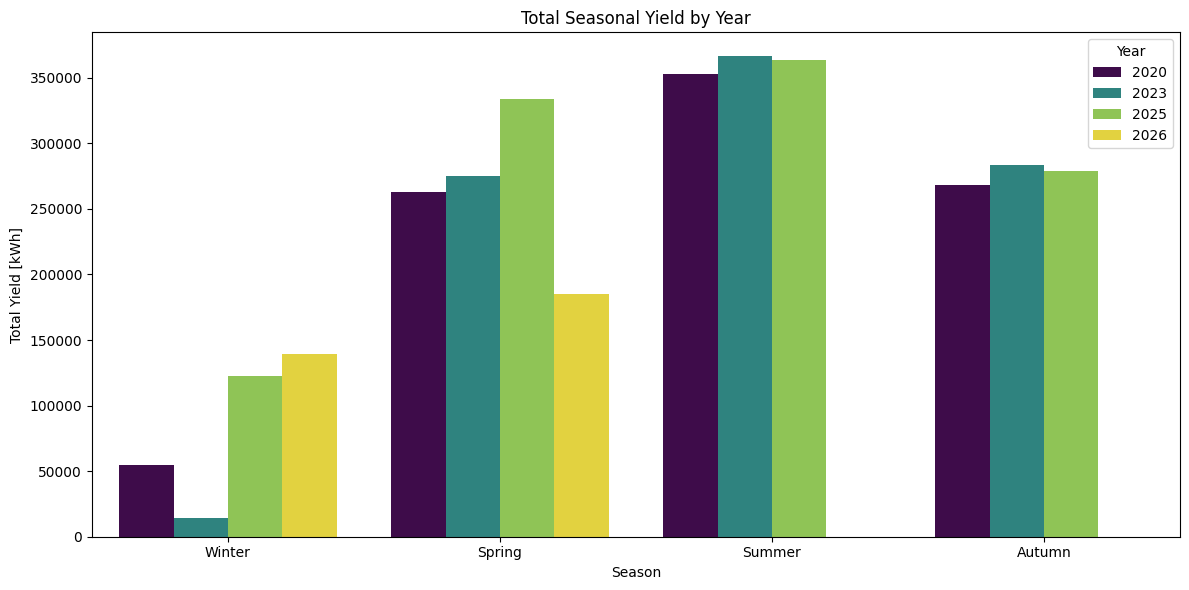

In [ ]:
plt.figure(figsize=(12, 6))
sns.barplot(x='Season', y='Total Yield [kWh]', hue='Year', data=seasonal_yield_by_year, palette='viridis')
plt.title('Total Seasonal Yield by Year')
plt.xlabel('Season')
plt.ylabel('Total Yield [kWh]')
plt.legend(title='Year')
plt.tight_layout()
plt.show()

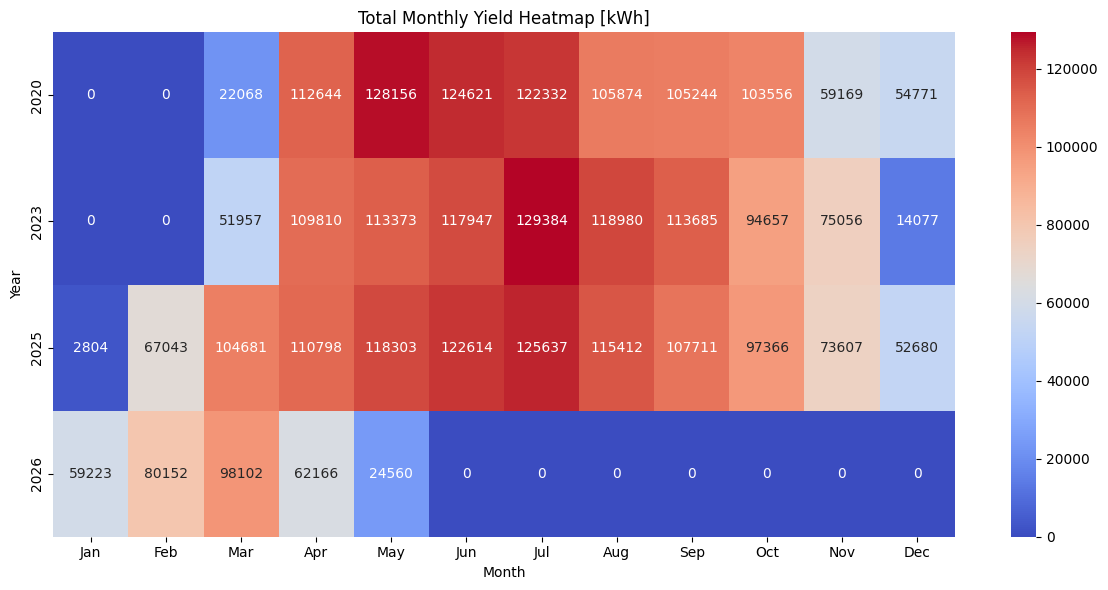

In [ ]:
plt.figure(figsize=(12, 6))
pivoted_yield = monthly_yearly_total_yield.pivot_table(index='Year', columns='Month', values=total_yield_col, observed=False)
sns.heatmap(pivoted_yield, annot=True, fmt=".0f", cmap='coolwarm')
plt.title('Total Monthly Yield Heatmap [kWh]')
plt.xlabel('Month')
plt.ylabel('Year')
plt.tight_layout()
plt.show()

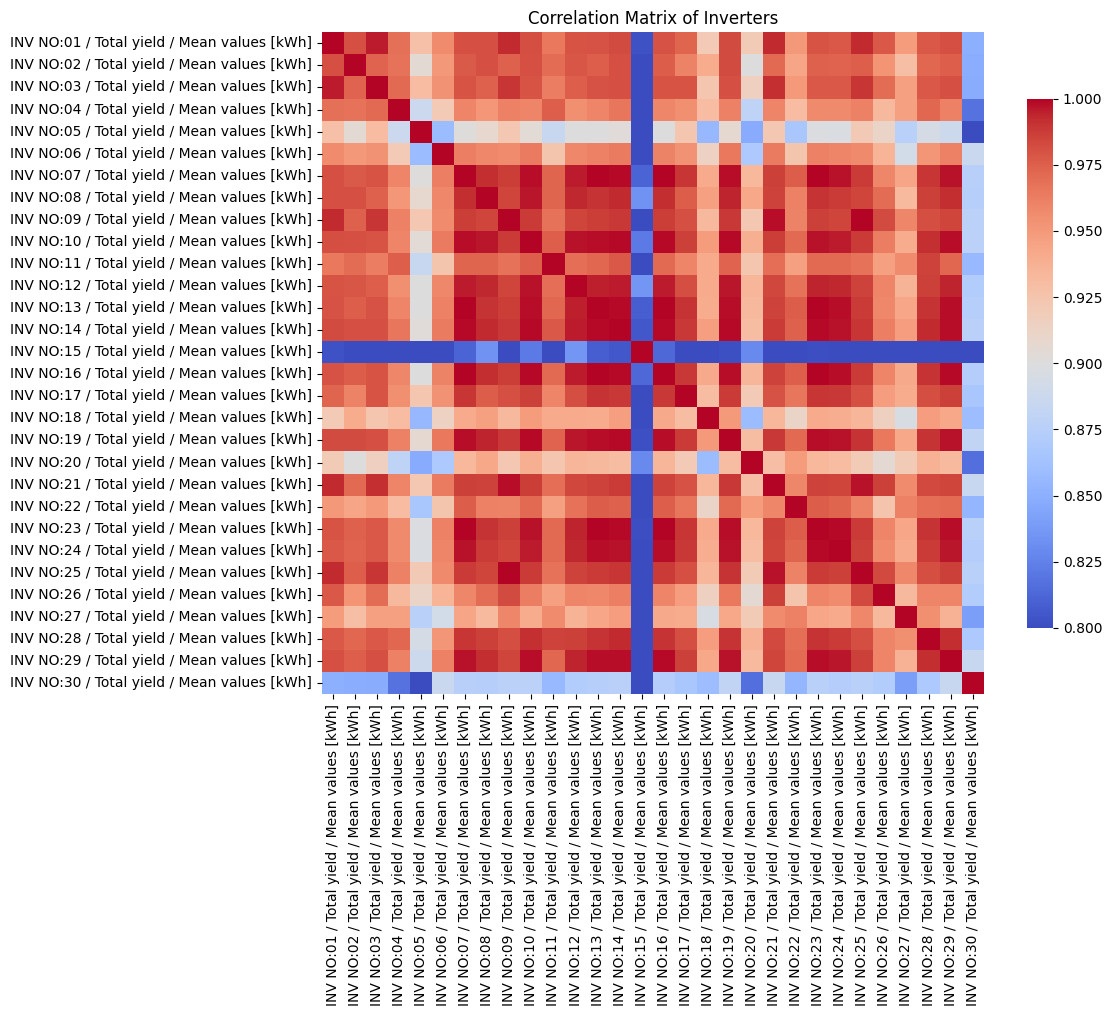

In [ ]:
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix,fmt=".2f" ,cmap='coolwarm',vmin=0.8,vmax=1.0,square=True,cbar_kws={"shrink": .8})
plt.title('Correlation Matrix of Inverters')
plt.tight_layout()

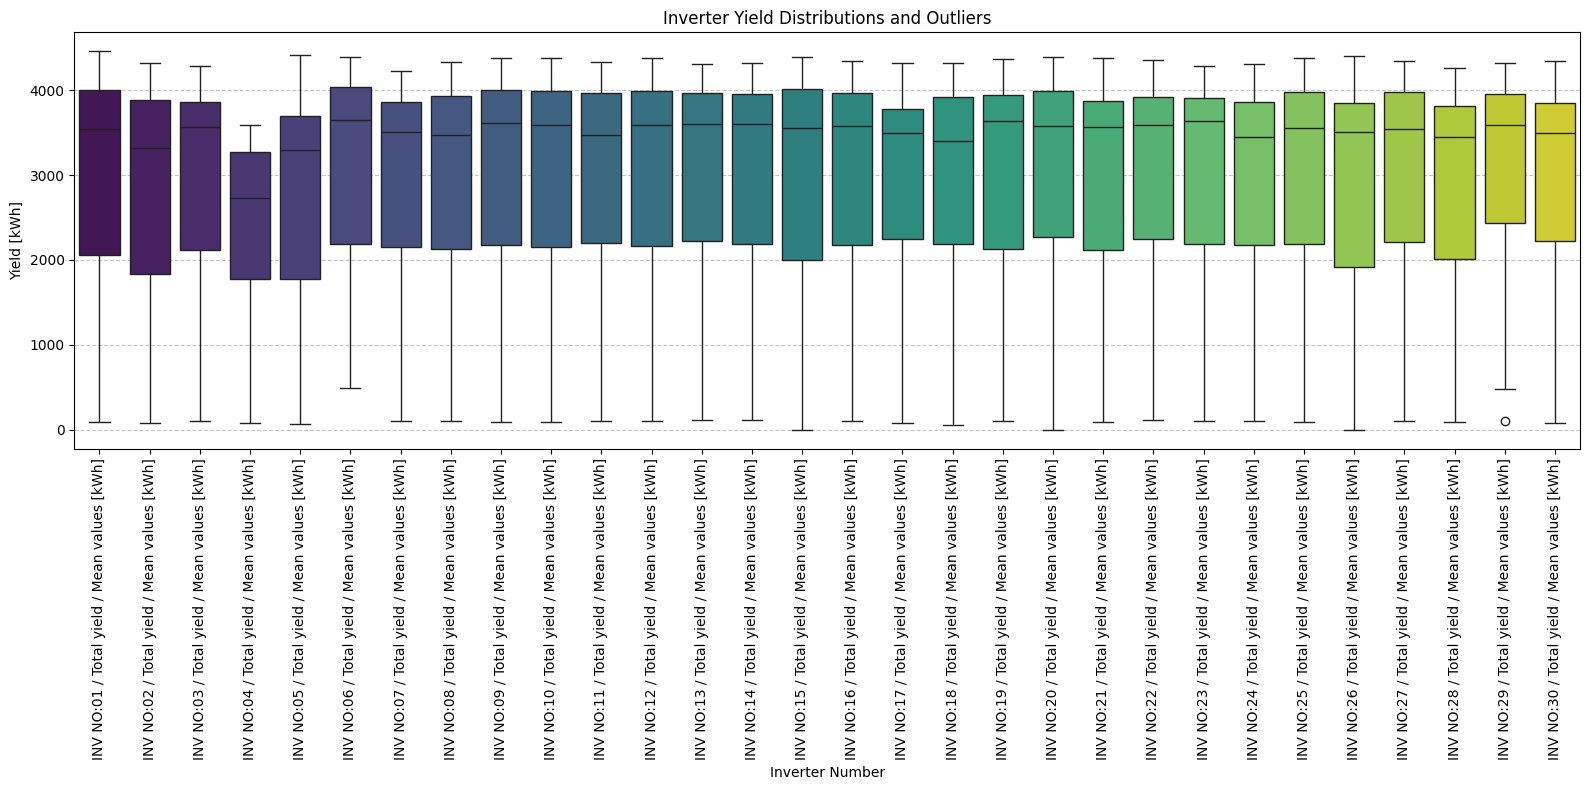

In [ ]:
plt.figure(figsize=(16, 8))
sns.boxplot(data=inverter_data, palette='viridis')
plt.title('Inverter Yield Distributions and Outliers')
plt.xlabel('Inverter Number')
plt.ylabel('Yield [kWh]')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

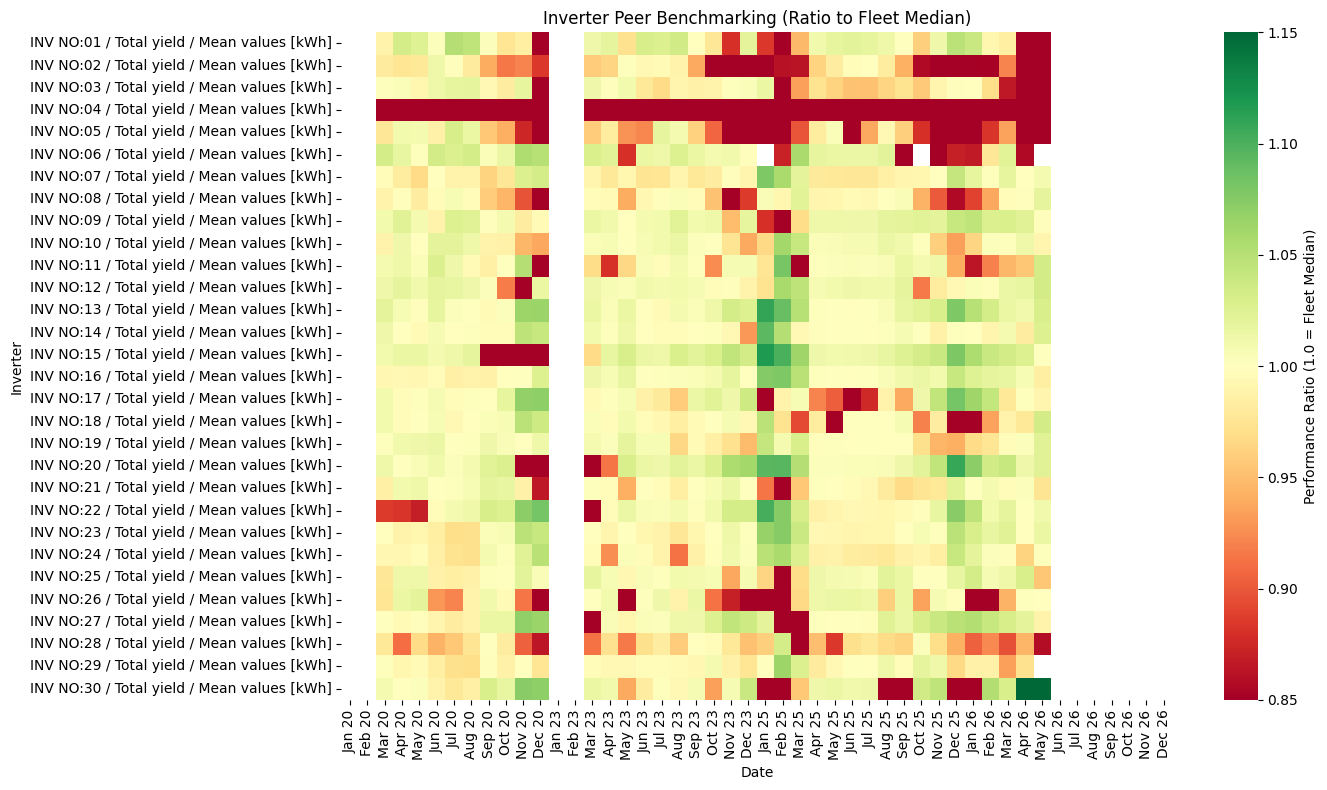

In [ ]:
plt.figure(figsize=(14, 8))
sns.heatmap(
    relative_performance.set_index('Date_Str')[inverter_cols].T,
    cmap='RdYlGn',
    vmin=0.85,
    vmax=1.15,
    annot=False,
    cbar_kws={'label': 'Performance Ratio (1.0 = Fleet Median)'}
)
plt.title('Inverter Peer Benchmarking')
plt.xlabel('Date')
plt.ylabel('Inverter')
plt.tight_layout()
plt.show()

/tmp/ipykernel_2128/16513057.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=annual_yield, x='Year', y=total_yield_col, ax=ax1, palette='Blues_d')


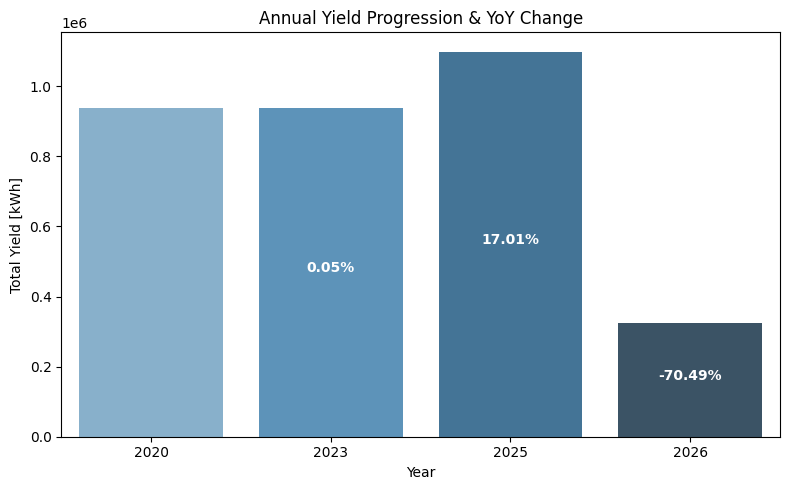

In [ ]:
fig, ax1 = plt.subplots(figsize=(8, 5))
sns.barplot(data=annual_yield, x='Year', y=total_yield_col, ax=ax1, palette='Blues_d')
ax1.set_ylabel('Total Yield [kWh]')
ax1.set_title('Annual Yield Progression & YoY Change')


for i, row in annual_yield.iterrows():
    if not np.isnan(row['annual_change']):
        ax1.text(i, row[total_yield_col] / 2, f"{row['annual_change']:.2f}%",
                 ha='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

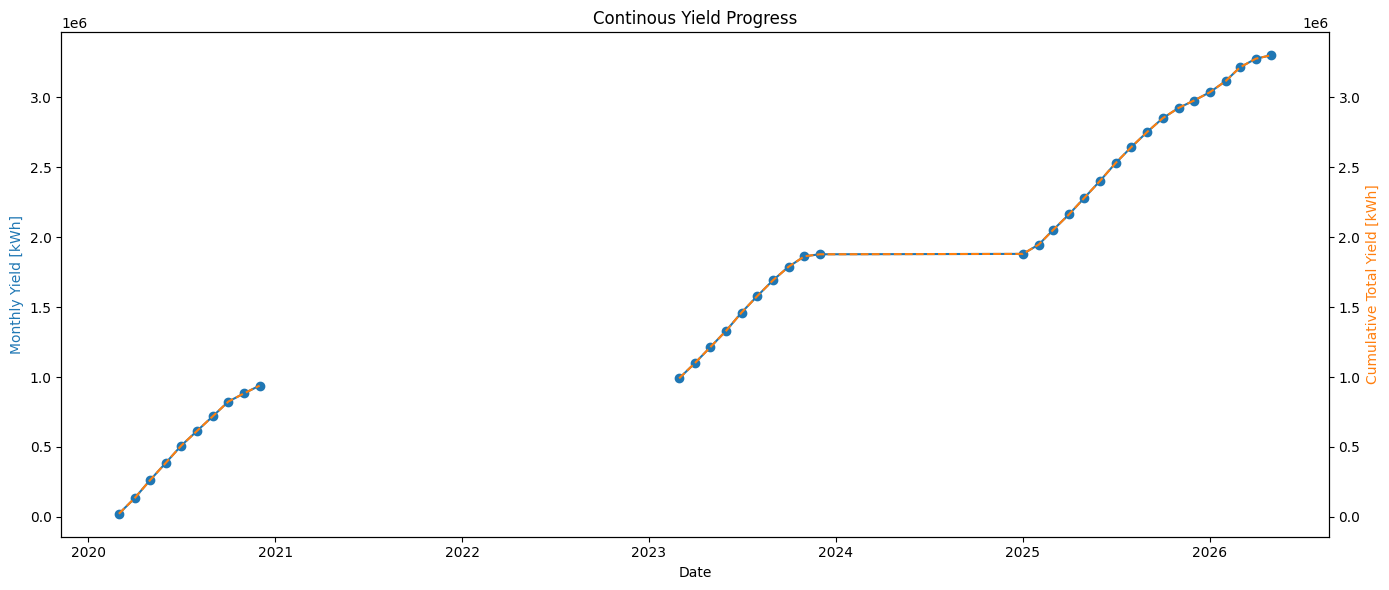

In [ ]:
solar_analysis_sorted = solar_analysis.sort_values('Datetime').reset_index(drop=True)
solar_analysis_sorted['Cumulative Yield'] = solar_analysis_sorted[total_yield_col].cumsum()

fig, ax1 = plt.subplots(figsize=(14, 6))
ax1.plot(solar_analysis_sorted['Datetime'], solar_analysis_sorted['Cumulative Yield'], color='tab:blue', marker='o', label= 'Monthly Yield')
ax1.set_xlabel('Date')
ax1.set_ylabel('Monthly Yield [kWh]', color='tab:blue')

ax2 = ax1.twinx()
ax2.plot(solar_analysis_sorted['Datetime'], solar_analysis_sorted['Cumulative Yield'], color='tab:orange', linestyle = '--' , label= 'Cumulative Yield')
ax2.set_ylabel('Cumulative Total Yield [kWh]', color='tab:orange')

plt.title("Continous Yield Progress")
fig.tight_layout()
plt.show()